# Gym Churn: Churn Prediction

This notebook trains two binary classification models, logistic regression and random forest, to predict which Model Fitness customers will churn in the following month, and compares them on accuracy, precision and recall.

In [1]:
# Libraries for data handling, modeling and evaluation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)  # show all columns in outputs

## 1. Data Preparation for Modeling

In [2]:
# Load the cleaned dataset prepared in notebook 01
gym_data = pd.read_csv('../data/gym_churn_clean.csv')
gym_data.head()

,gender,near_location,partner,promo_friends,phone,contract_period,group_visits,age,avg_additional_charges_total,month_to_end_contract,lifetime,avg_class_frequency_total,avg_class_frequency_current_month,churn
0,1,1,1,1,0,6,1,29,14.227470,5,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1,3,1.113884,1.120078,0


In [3]:
# Features (X) and target (y)
# One feature from each highly correlated pair is dropped to avoid multicollinearity
X = gym_data.drop(
    columns=['churn', 'month_to_end_contract', 'avg_class_frequency_total'])
y = gym_data['churn']

print(X.shape, y.shape)

(4000, 11) (4000,)


In [4]:
# Split into training and validation sets (80/20)
# stratify=y keeps the same proportion of churned customers in both sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)

print(X_train.shape, X_valid.shape)

(3200, 11) (800, 11)


In [5]:
# Standardize features: fit the scaler on the training set only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

### Observations
- The target variable is `churn`; all other features are used as predictors, except `month_to_end_contract` and `avg_class_frequency_total`, which were dropped to avoid multicollinearity (0.97 and 0.95 correlation with `contract_period` and `avg_class_frequency_current_month`).
- The data was split into training (80%) and validation (20%) sets, stratified by churn to keep the same churn rate in both.
- Features were standardized with a scaler fitted on the training set only, so the validation set remains unseen by the model.

## 2. Model Training

Two binary classification models are trained to predict churn: logistic regression, a simple and interpretable linear model, and random forest, an ensemble of decision trees that can capture non-linear relationships. Both are evaluated on the validation set using accuracy, precision and recall.

In [6]:
# Function to print accuracy, precision and recall for a model's predictions
def print_metrics(y_true, y_pred, title):
    print(title)
    print('Accuracy:  {:.2f}'.format(accuracy_score(y_true, y_pred)))
    print('Precision: {:.2f}'.format(precision_score(y_true, y_pred)))
    print('Recall:    {:.2f}'.format(recall_score(y_true, y_pred)))

In [7]:
# Baseline: accuracy of a model that always predicts "stays" (0)
print('Baseline accuracy: {:.2f}'.format((y_valid == 0).mean()))

Baseline accuracy: 0.73


### 2.1 Logistic Regression

In [8]:
# Initialize and train the logistic regression model
lr_model = LogisticRegression(random_state=0)
lr_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

In [9]:
# Predict churn (0/1) and churn probability on the validation set
lr_predictions = lr_model.predict(X_valid_scaled)
lr_probabilities = lr_model.predict_proba(X_valid_scaled)[:, 1]

print_metrics(y_valid, lr_predictions, 'Logistic Regression metrics:')

Logistic Regression metrics:
Accuracy:  0.92
Precision: 0.85
Recall:    0.84


In [10]:
# Churn probability for the first validation customers, next to the actual outcome
lr_results = pd.DataFrame({
    'churn_probability': lr_probabilities.round(2),
    'predicted': lr_predictions,
    'actual': y_valid.values
})
lr_results.head(10)

,churn_probability,predicted,actual
0,0.84,1,1
1,0.09,0,0
2,0.01,0,0
3,0.03,0,0
4,0.01,0,0
5,0.00,0,0
6,0.00,0,0
7,0.10,0,0
8,0.90,1,1
9,0.00,0,0


**Logistic regression results:**
- Accuracy is 0.92, well above the 0.73 that a model predicting "stays" for every customer would achieve.
- Precision is 0.85: of the customers predicted to churn, 85% actually did.
- Recall is 0.84: the model identifies 84% of the customers who actually churned.
- Precision and recall are balanced, so the model is not trading false alarms for missed churners.
- The model also returns a churn probability for each customer, which can be used to rank customers by risk and prioritize retention actions.

### 2.2 Random Forest

In [11]:
# Initialize and train the random forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=0)
rf_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [12]:
# Predict churn (0/1) and churn probability on the validation set
rf_predictions = rf_model.predict(X_valid_scaled)
rf_probabilities = rf_model.predict_proba(X_valid_scaled)[:, 1]

print_metrics(y_valid, rf_predictions, 'Random Forest metrics:')

Random Forest metrics:
Accuracy:  0.91
Precision: 0.85
Recall:    0.77


In [13]:
# Churn probability for the first validation customers, next to the actual outcome
rf_results = pd.DataFrame({
    'churn_probability': rf_probabilities.round(2),
    'predicted': rf_predictions,
    'actual': y_valid.values
})
rf_results.head(10)

,churn_probability,predicted,actual
0,0.90,1,1
1,0.13,0,0
2,0.02,0,0
3,0.02,0,0
4,0.03,0,0
5,0.04,0,0
6,0.00,0,0
7,0.20,0,0
8,0.87,1,1
9,0.03,0,0


**Random forest results:**
- Accuracy is 0.91 and precision is 0.85, very similar to the logistic regression.
- Recall is lower (0.77): the random forest identifies fewer of the customers who actually churned, missing more potential churners.

## 3. Model Comparison

In [14]:
# Side-by-side comparison of both models on the validation set
comparison = pd.DataFrame({
    'Logistic Regression': [accuracy_score(y_valid, lr_predictions),
                            precision_score(y_valid, lr_predictions),
                            recall_score(y_valid, lr_predictions)],
    'Random Forest': [accuracy_score(y_valid, rf_predictions),
                      precision_score(y_valid, rf_predictions),
                      recall_score(y_valid, rf_predictions)]
}, index=['Accuracy', 'Precision', 'Recall'])

comparison.map('{:.2f}'.format)

,Logistic Regression,Random Forest
Accuracy,0.92,0.91
Precision,0.85,0.85
Recall,0.84,0.77


### Conclusion
- Both models clearly outperform the baseline accuracy of 0.73.
- Accuracy and precision are almost identical for both models, but logistic regression has a higher recall (0.84 vs 0.77), identifying more of the customers who actually churned.
- For a retention strategy, missing a customer who is about to leave is more costly than contacting one who would have stayed, so recall is the most relevant metric.
- Logistic regression is therefore the better model for this problem. It is also simpler and easier to interpret, which makes it more practical to explain to the business.
- Its strong performance suggests that the relationships between features and churn are mostly linear, as observed in the EDA.

## 4. Factors Influencing Churn

In [18]:
# Logistic regression coefficients: effect of each (standardized) feature on churn
coefficients = pd.DataFrame({
    'feature': X.columns,
    'coefficient': lr_model.coef_[0]
}).sort_values('coefficient')

coefficients.style.format({'coefficient': '{:.2f}'})

,feature,coefficient
9,lifetime,-3.65
5,contract_period,-1.41
10,avg_class_frequency_current_month,-1.30
7,age,-1.17
8,avg_additional_charges_total,-0.57
6,group_visits,-0.38
3,promo_friends,-0.15
4,phone,-0.08
1,near_location,-0.06
2,partner,-0.06


In [16]:
# Readable feature names for the chart
readable_labels = {
    'gender': 'Gender',
    'near_location': 'Near Location',
    'partner': 'Partner',
    'promo_friends': 'Promo Friends',
    'phone': 'Phone',
    'contract_period': 'Contract Period',
    'group_visits': 'Group Visits',
    'age': 'Age',
    'avg_additional_charges_total': 'Additional Charges',
    'lifetime': 'Lifetime',
    'avg_class_frequency_current_month': 'Weekly Visits (Current Month)'
}
coefficients['feature'] = coefficients['feature'].map(readable_labels)

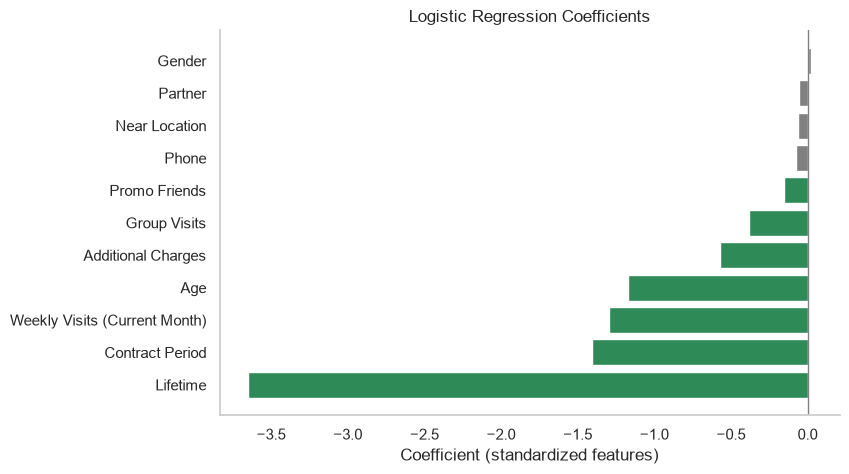

In [17]:
# Green: lowers churn risk, red: raises churn risk
colors = []
for value in coefficients['coefficient']:
    if abs(value) < 0.1:
        colors.append('grey')
    elif value < 0:
        colors.append('seagreen')
    else:
        colors.append('indianred')

plt.figure(figsize=(8, 5))
plt.barh(coefficients['feature'], coefficients['coefficient'], color=colors)
plt.axvline(0, color='grey', linewidth=1)
plt.title('Logistic Regression Coefficients')
plt.xlabel('Coefficient (standardized features)')
plt.grid(False)
sns.despine()
plt.show()

### Observations
- Lifetime is by far the strongest factor (coefficient -3.65): the longer a customer has been with the gym, the lower their churn risk. This confirms the EDA, where churn was concentrated in the first months.
- Contract period (-1.41), current-month visit frequency (-1.30) and age (-1.17) form a second group of strong factors. These are the same features most correlated with churn in the EDA, although in the model lifetime clearly outweighs them.
- Additional charges (-0.57), group visits (-0.38) and the bring-a-friend promo (-0.15) have a smaller but still negative effect.
- Partner and near location showed clear differences in churn rate in the EDA, but have coefficients close to zero here. Each coefficient measures a feature's effect while holding the others constant, so their effect is likely already captured by related features, such as partner employees signing longer contracts and joining through the promo.
- Gender and phone have no meaningful effect, consistent with the EDA.
- All relevant coefficients are negative: retention is driven by commitment (contract length, time as a member) and engagement (frequent visits, group sessions, additional services). As with correlation, these coefficients describe associations, not causes.